# 14 · Cause test for sign blindness: constant padding, evaluated on a third, untouched file

**Hypothesis (from notebooks 10–11):** amplitude encoding of centred (standardised) inputs fails (AUC ≈ 0.62) because the encoding cannot distinguish $x$ from $-x$ (Gurgul & Prinz 2026), and after centring quark and gluon jets point in nearly opposite directions (for a balanced training subsample standardised on itself, the two class means are exactly opposite: μ_q = −μ_g).

**Test:** put a constant $c$ in the unused 4th amplitude before normalisation (Schuld et al. 2020):
$|\psi_c(x)\rangle = (x_1, x_2, x_3, c)/\sqrt{\lVert x\rVert^2 + c^2}$. This makes the map injective (no sign or scale ambiguity) with no extra qubits.
If sign blindness is the cause, padding should recover standardised inputs to the level of min-max / classical RBF-SVM.
$c$ is a bandwidth: for $c \gg \lVert x\rVert$ the kernel tends to an RBF kernel and concentrates, so $c$ is tuned.
The padded kernel is a cosine-normalised degree-2 polynomial kernel: it is classically computable; no quantum advantage is implied.

## Protocol fixed before the run
`amplitude_kernel_padded` (src/kernels.py) was committed in 1b38d66 before the run. This notebook was **not** part of that commit; its cell sources were verified (MD5 of all cell sources) to be identical to the version written before the run (checked before the review notes below were added).
- **Evaluation file:** `JetNtuple_RunIISummer16_13TeV_MC_8.h5`, never used before. Each model is evaluated on it **once**.
- **Training:** development file (`_MC_1`), balanced 400-jet subsamples, **10 seeds** (0–9), event-level split as before.
- **Variants:** standardised zero-pad, standardised c-pad, min-max zero-pad, min-max c-pad, classical RBF-SVM (standardised).
- **Tuning:** 5-fold CV inside each training subsample; $c = k \cdot \mathrm{median}\lVert x\rVert$ (median over the training subsample) with $k \in \{0.5, 1, 1.5, 2, 3, 5, 8\}$; $C \in \{10^{-2}, \dots, 10^{6}\}$. Tuned and evaluated at the **same** shot budget: exact and 1000 shots.
- **Reported:** mean ± std (ddof = 1) over 10 seeds; chosen $k$ and $C$; off-diagonal kernel mean and variance; inclusive and pT-reweighted AUC.

> **Note added after the independent review (11 Nov 2026).**

1. Constant padding restores **both** the sign and the norm of x, so this test alone does not separate the two. Supporting the sign: min-max inputs also lose the norm and still score well. Notebook 15 (part B) separates them with encodings that restore only one.
2. For large c the padded kernel approaches an RBF kernel, and k = 8 (the grid edge) was chosen in 4/10 exact seeds. Notebook 15 shows the AUC as a function of k.
3. The printed summary line in section 4 says "pre-registered (commit before run)"; see the protocol section above for what was actually committed.

In [1]:
import sys
sys.path.insert(0, "src")

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
warnings.filterwarnings("ignore", category=ConvergenceWarning)

from jet_data import load_jets, select_quark_gluon, feature_matrix, event_level_split, balanced_subsample, BOOKKEEPING
from kernels import preprocess, amplitude_kernel, amplitude_kernel_padded, shot_noise, concentration
from figure_style import set_style, save, COLORS

set_style()
SEED = 42
SEEDS = list(range(10))
N_PER_CLASS = 200
QGL_INPUTS = ("QG_mult", "QG_ptD", "QG_axis2")
C_GRID = np.logspace(-2, 6, 9)
K_GRID = [0.5, 1.0, 1.5, 2.0, 3.0, 5.0, 8.0]
BUDGETS = [None, 1000]                    # None = exact kernel
MAX_ITER = 200_000
DEV_PATH = Path("Data/JetNtuple_RunIISummer16_13TeV_MC_1.h5")
THIRD_PATH = Path("Data/JetNtuple_RunIISummer16_13TeV_MC_8.h5")
RESULTS = Path("results")
assert THIRD_PATH.exists(), f"third file not found: {THIRD_PATH}"

def load(path):
    j = select_quark_gluon(load_jets(path=path, features=QGL_INPUTS + ("jetPt",), extra=BOOKKEEPING), require_loose_id=True)
    return {"y": j["label"], "X": feature_matrix(j, features=QGL_INPUTS), "pt": np.asarray(j["jetPt"], float), "jets": j}

dev, third = load(DEV_PATH), load(THIRD_PATH)
train, test = event_level_split(dev["jets"], test_fraction=0.3, seed=SEED)
keys = lambda D: set(zip(np.asarray(D["jets"]["run"]).tolist(), np.asarray(D["jets"]["lumi"]).tolist(), np.asarray(D["jets"]["event"]).tolist()))
print(f"dev {len(dev['y'])} jets; third file {len(third['y'])} jets, quark fraction {third['y'].mean():.3f}; shared events: {len(keys(dev) & keys(third))}")

dev 13912 jets; third file 84498 jets, quark fraction 0.373; shared events: 0


## 1. Run (about 10 minutes; progress per seed)

In [2]:
VARIANTS = {   # name -> (preprocessing, padded?)
    "standardised, zero-pad": ("standard", False),
    "standardised, c-pad":    ("standard", True),
    "min-max, zero-pad":      ("minmax", False),
    "min-max, c-pad":         ("minmax", True),
}

def cv_auc(K, labels, folds, C):
    out = []
    for tr, va in folds:
        svc = SVC(kernel="precomputed", C=C, max_iter=MAX_ITER).fit(K[np.ix_(tr, tr)], labels[tr])
        out.append(roc_auc_score(labels[va], svc.decision_function(K[np.ix_(va, tr)])))
    return np.mean(out)

records, third_scores = [], {}
for s in SEEDS:
    idx = balanced_subsample(dev["y"], train, N_PER_CLASS, seed=s)
    y_tr = dev["y"][idx]
    folds = list(StratifiedKFold(5, shuffle=True, random_state=s).split(idx, y_tr))
    for name, (prep, padded) in VARIANTS.items():
        A, T = preprocess(prep, dev["X"][idx], third["X"])
        med = float(np.median(np.linalg.norm(A, axis=1)))
        for B in BUDGETS:
            rng = np.random.default_rng(9000 + 31 * s + (B or 0))
            best = (-1, None, None, None)
            for k in (K_GRID if padded else [None]):
                kern = (lambda P, Q, c=k * med: amplitude_kernel_padded(P, Q, c)) if padded else amplitude_kernel
                K_tr = kern(A, A)
                K_fit = shot_noise(K_tr, B, rng, symmetric=True) if B else K_tr
                for C in C_GRID:
                    sc = cv_auc(K_fit, y_tr, folds, C)
                    if sc > best[0]:
                        best = (sc, C, k, K_fit)
            cv_score, C, k, K_fit = best
            kern = (lambda P, Q, c=k * med: amplitude_kernel_padded(P, Q, c)) if padded else amplitude_kernel
            K_te = kern(T, A)
            if B:
                K_te = shot_noise(K_te, B, rng)
            sc = SVC(kernel="precomputed", C=C, max_iter=MAX_ITER).fit(K_fit, y_tr).decision_function(K_te)
            km, kv = concentration(kern(A, A))
            label = f"{name} ({'exact' if B is None else f'{B} shots'})"
            third_scores.setdefault(label, []).append(sc)
            records.append({"variant": name, "budget": B or "exact", "seed": s, "C": float(C), "k": k, "c": None if k is None else k * med,
                            "kernel_mean": float(km), "kernel_var": float(kv), "cv_auc": cv_score,
                            "auc_third": roc_auc_score(third["y"], sc)})
    sc_ = StandardScaler().fit(dev["X"][idx])
    gs = GridSearchCV(SVC(kernel="rbf", max_iter=MAX_ITER), {"C": C_GRID[:7], "gamma": ["scale", 0.01, 0.1, 1.0]},
                      scoring="roc_auc", cv=folds).fit(sc_.transform(dev["X"][idx]), y_tr)
    sc = gs.best_estimator_.decision_function(sc_.transform(third["X"]))
    third_scores.setdefault("classical RBF-SVM (standardised)", []).append(sc)
    records.append({"variant": "classical RBF-SVM (standardised)", "budget": "exact", "seed": s, "auc_third": roc_auc_score(third["y"], sc)})
    print(f"seed {s} done", flush=True)
json.dump({"records": records}, open(RESULTS / "constant_padding_third_file.json", "w"), indent=2)

seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done
seed 5 done
seed 6 done
seed 7 done
seed 8 done
seed 9 done


## 2. Results on the third file (mean ± std over 10 seeds)

pT-reweighted AUC: gluon jets reweighted to the quark pT spectrum (as in notebook 13), so pT itself carries no information.

In [3]:
y3, pt3 = third["y"], third["pt"]
edges_w = np.logspace(np.log10(30), np.log10(pt3.max() * 1.001), 31)
hq, _ = np.histogram(pt3[y3 == 1], edges_w, density=True); hg, _ = np.histogram(pt3[y3 == 0], edges_w, density=True)
b_of = np.clip(np.digitize(pt3, edges_w) - 1, 0, len(hq) - 1)
w3 = np.where(y3 == 1, 1.0, np.divide(hq, hg, out=np.zeros_like(hq), where=hg > 0)[b_of])
print(f"check: AUC of pT, inclusive {roc_auc_score(y3, pt3):.3f}, reweighted {roc_auc_score(y3, pt3, sample_weight=w3):.3f}\n")

print(f"{'model':46s} {'inclusive':>14s} {'pT-reweighted':>14s}   chosen k / C (median)   K mean / K var")
summary = {}
for label, sc_list in third_scores.items():
    inc = [roc_auc_score(y3, sc) for sc in sc_list]
    rw = [roc_auc_score(y3, sc, sample_weight=w3) for sc in sc_list]
    summary[label] = {"inclusive": inc, "reweighted": rw}
    rs = [r for r in records if f"{r['variant']} ({'exact' if r['budget'] == 'exact' else str(r['budget']) + ' shots'})" == label]
    extra = ""
    if rs and "C" in rs[0]:
        kk = [r["k"] for r in rs if r["k"] is not None]
        extra = (f"k {np.median(kk):g}, " if kk else "") + f"C {np.median([r['C'] for r in rs]):g}   {np.mean([r['kernel_mean'] for r in rs]):.3f} / {np.mean([r['kernel_var'] for r in rs]):.1e}"
    print(f"{label:46s} {np.mean(inc):7.3f} ± {np.std(inc, ddof=1):.3f} {np.mean(rw):7.3f} ± {np.std(rw, ddof=1):.3f}   {extra}")
json.dump({"records": records, "summary": summary}, open(RESULTS / "constant_padding_third_file.json", "w"), indent=2)
print("\nsaved results/constant_padding_third_file.json")

check: AUC of pT, inclusive 0.667, reweighted 0.501

model                                               inclusive  pT-reweighted   chosen k / C (median)   K mean / K var
standardised, zero-pad (exact)                   0.604 ± 0.017   0.622 ± 0.019   C 500.5   0.406 / 1.0e-01
standardised, zero-pad (1000 shots)              0.604 ± 0.014   0.622 ± 0.016   C 0.55   0.406 / 1.0e-01
standardised, c-pad (exact)                      0.793 ± 0.003   0.754 ± 0.014   k 5, C 10   0.845 / 2.2e-02
standardised, c-pad (1000 shots)                 0.791 ± 0.002   0.758 ± 0.012   k 3, C 1   0.711 / 4.8e-02
min-max, zero-pad (exact)                        0.794 ± 0.003   0.763 ± 0.009   C 0.1   0.648 / 6.9e-02
min-max, zero-pad (1000 shots)                   0.792 ± 0.003   0.761 ± 0.013   C 0.1   0.648 / 6.9e-02
min-max, c-pad (exact)                           0.793 ± 0.004   0.758 ± 0.013   k 1.25, C 1   0.830 / 2.5e-02
min-max, c-pad (1000 shots)                      0.788 ± 0.009   0.754 ± 0.011

## 3. Figure

saved figures/fig15_constant_padding.pdf and .png


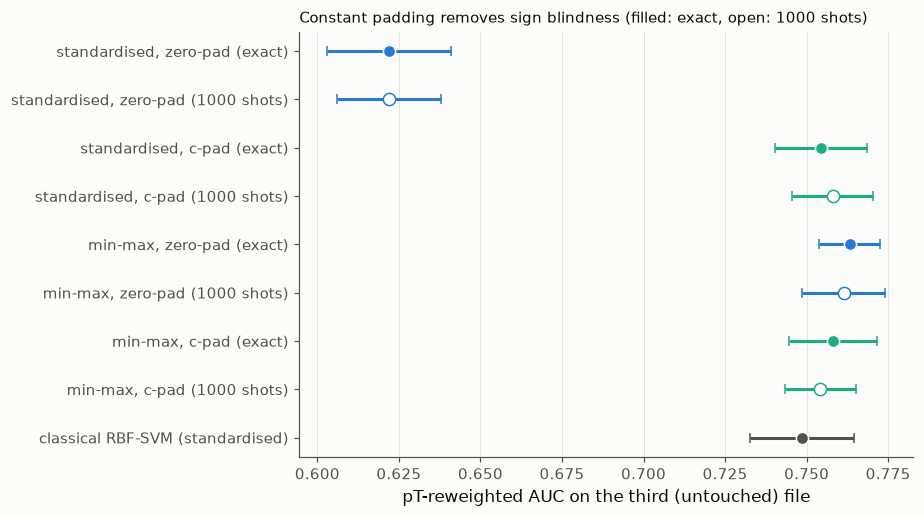

In [4]:
ORDER = [l for v in VARIANTS for l in (f"{v} (exact)", f"{v} (1000 shots)")] + ["classical RBF-SVM (standardised)"]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ypos = np.arange(len(ORDER))[::-1]
for yp, label in zip(ypos, ORDER):
    rw = summary[label]["reweighted"]
    col = COLORS["reference"] if label.startswith("classical") else (COLORS["series1"] if "zero-pad" in label else COLORS["series3"])
    filled = "exact" in label or label.startswith("classical")
    ax.errorbar(np.mean(rw), yp, xerr=np.std(rw, ddof=1), fmt="o", color=col, mfc=col if filled else "white",
                markersize=8, markeredgecolor=col if not filled else "white", capsize=3)
ax.set_yticks(ypos, ORDER)
ax.set_xlabel("pT-reweighted AUC on the third (untouched) file")
ax.set_title("Constant padding removes sign blindness (filled: exact, open: 1000 shots)", loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "fig15_constant_padding")
plt.show()

## 4. Summary for the research log

In [5]:
print(f"- Constant-padding cause test, third file {THIRD_PATH.name} ({len(third['y'])} jets), 10 seeds, pre-registered (commit before run):")
for label in ORDER:
    print(f"  - {label}: inclusive {np.mean(summary[label]['inclusive']):.3f}, pT-reweighted {np.mean(summary[label]['reweighted']):.3f} ± {np.std(summary[label]['reweighted'], ddof=1):.3f}")

- Constant-padding cause test, third file JetNtuple_RunIISummer16_13TeV_MC_8.h5 (84498 jets), 10 seeds, pre-registered (commit before run):
  - standardised, zero-pad (exact): inclusive 0.604, pT-reweighted 0.622 ± 0.019
  - standardised, zero-pad (1000 shots): inclusive 0.604, pT-reweighted 0.622 ± 0.016
  - standardised, c-pad (exact): inclusive 0.793, pT-reweighted 0.754 ± 0.014
  - standardised, c-pad (1000 shots): inclusive 0.791, pT-reweighted 0.758 ± 0.012
  - min-max, zero-pad (exact): inclusive 0.794, pT-reweighted 0.763 ± 0.009
  - min-max, zero-pad (1000 shots): inclusive 0.792, pT-reweighted 0.761 ± 0.013
  - min-max, c-pad (exact): inclusive 0.793, pT-reweighted 0.758 ± 0.013
  - min-max, c-pad (1000 shots): inclusive 0.788, pT-reweighted 0.754 ± 0.011
  - classical RBF-SVM (standardised): inclusive 0.789, pT-reweighted 0.749 ± 0.016
